# 06 — Following one real car across a line

Imagine a security guard drawing a line on a camera picture. A car moving from
one side to the other is one **image-line crossing**. The camera itself may move,
so this does not automatically mean a car entered a parking facility.

This lesson displays a completed, saved development experiment. It performs no
new detector inference, training, tuning, or final evaluation. The scene is from
**DAVIS2017 `car-turn`**, source **SRC-DS-012**, with publisher foreground labels.
The masks label a selected car, not every road user. The reserved `car-roundabout`
sequence stays unopened. Physical fps is unknown: horizontal axes use frame index.

[DAVIS authors / data](https://davischallenge.org/), Pont-Tuset et al. (2017),
Perazzi et al. (2016). Aggregate dataset licence:
[CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/).
Original bytes and source-ID correction records are preserved locally.

In [1]:
from pathlib import Path
import json, hashlib, sys
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display, HTML
from html import escape

def table(rows, columns):
    head = ''.join('<th style="padding:8px;text-align:left">'+escape(str(c))+'</th>' for c in columns)
    body = ''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #ddd">'+escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)
    display(HTML('<table style="border-collapse:collapse"><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'))

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/automation_state.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/automation_state.json').exists(), 'Open this notebook inside the project'
RUN = "DAVIS-SETUP-20261025T141839144041Z"
folder = ROOT / 'experiments/results' / RUN
run = json.loads((folder / 'run.json').read_text(encoding='utf-8'))
protocol = json.loads((folder / 'protocol.json').read_text(encoding='utf-8'))
cache = ROOT / protocol['cache_path']
assert hashlib.sha256(cache.read_bytes()).hexdigest() == protocol['cache_sha256']
assert hashlib.sha256((folder/'setup.json').read_bytes()).hexdigest() == run['setup_sha256']
records = json.loads(cache.read_text(encoding='utf-8'))
replay = json.loads((folder / 'replay.json').read_text(encoding='utf-8'))
manifest = json.loads((ROOT / 'data/manifests/davis_car_sequences_v2.json').read_text(encoding='utf-8'))
print('Saved development run:', RUN)
print('No new inference; source:', protocol['source_ids'][0])

Saved development run: DAVIS-SETUP-20261025T141839144041Z
No new inference; source: SRC-DS-012


## 1. Set up the line before scoring

Only the labelled boxes in the first five frames choose the line. Their initial
left/right motion sets its direction; a fixed rule places it half a car width
ahead, with a minimum 24-pixel offset. Frames 5–79 are then scored. There is one
placement, no search for the line giving the best score. Because the setup uses
publisher labels, this resembles an operator setting up a view; it is **not
automatic parking-entrance discovery**.

The midpoint line from the earlier experiment had no reference crossings. This
new rule is another test on reused development footage, not a fresh final exam.

In [2]:
setup = run['setup']
table([[str(setup['setup_frames']), setup['initial_horizontal_displacement_pixels'],
        setup['gate_x'], setup['uses_labelled_setup']]],
      ['Setup frames', 'Initial horizontal motion (pixels)', 'Line x-coordinate (pixels)', 'Label-assisted setup'])

Setup frames,Initial horizontal motion (pixels),Line x-coordinate (pixels),Label-assisted setup
"[0, 1, 2, 3, 4]",-8.0,694,True


## 2. Compare the publisher label with our prediction

The green box is derived from the publisher foreground mask. Orange is the
predicted track box. Blue is our line. The chart follows the labelled car centre
through frame indices; it does not measure speed or elapsed seconds. One
reference crossing and one matched prediction occur at frame 22.

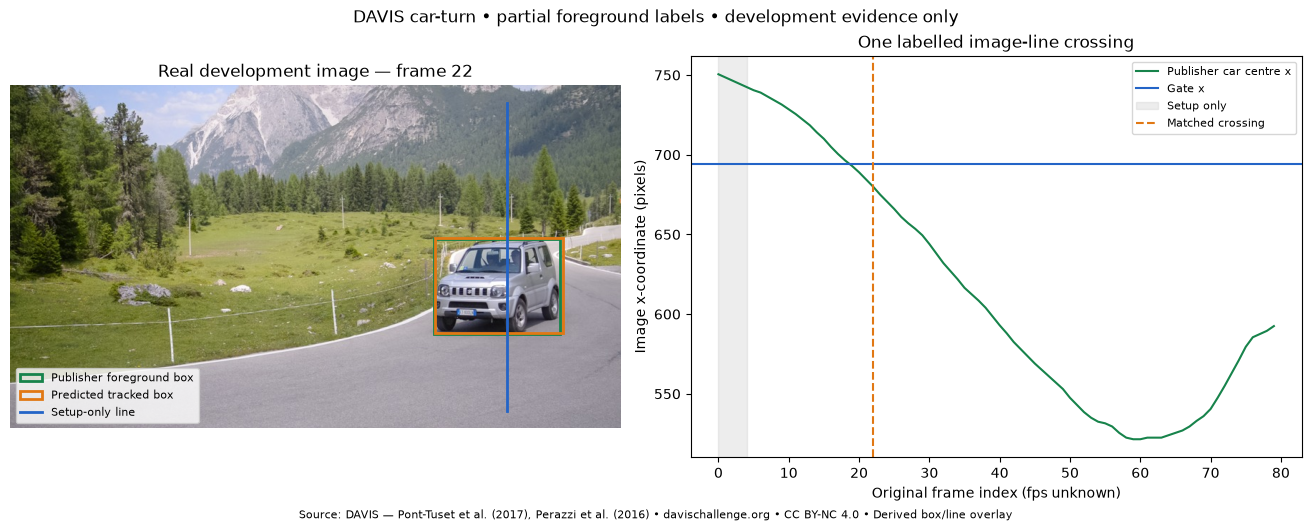

In [3]:
event = run['reference_events'][0]
index = event['frame_index']
member = next(r for r in manifest['frames'] if r['sequence']=='car-turn' and r['frame_index']==index)
image_path = ROOT / member['image']
assert hashlib.sha256(image_path.read_bytes()).hexdigest() == member['image_sha256']
with Image.open(image_path) as image:
    photo = image.convert('RGB').copy()
ref_box = records[index]['reference_objects'][0]['box']
matched_id = replay[index]['matched_track_id']
track = next(t for t in replay[index]['tracking']['tracks'] if t['track_id']==matched_id)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
axes[0].imshow(photo)
for box, colour, name in [(ref_box, '#17834b', 'Publisher foreground box'),
                           (track['box'], '#e17814', 'Predicted tracked box')]:
    axes[0].add_patch(Rectangle((box[0],box[1]), box[2]-box[0], box[3]-box[1],
                                fill=False, edgecolor=colour, linewidth=2, label=name))
line = run['gate_config']['line']
axes[0].plot([p[0] for p in line], [p[1] for p in line], color='#2364c7', linewidth=2, label='Setup-only line')
axes[0].set_title(f'Real development image — frame {index}')
axes[0].axis('off')
axes[0].legend(loc='lower left', fontsize=8)
xs = [sum(r['reference_objects'][0]['box'][::2])/2 for r in records]
axes[1].plot(range(len(xs)), xs, color='#17834b', label='Publisher car centre x')
axes[1].axhline(setup['gate_x'], color='#2364c7', label='Gate x')
axes[1].axvspan(0,4, color='#cccccc', alpha=.35, label='Setup only')
axes[1].axvline(index, color='#e17814', linestyle='--', label='Matched crossing')
axes[1].set(xlabel='Original frame index (fps unknown)', ylabel='Image x-coordinate (pixels)',
            title='One labelled image-line crossing')
axes[1].legend(fontsize=8)
fig.suptitle('DAVIS car-turn • partial foreground labels • development evidence only', fontsize=12)
fig.supxlabel('Source: DAVIS — Pont-Tuset et al. (2017), Perazzi et al. (2016) • davischallenge.org • CC BY-NC 4.0 • Derived box/line overlay', fontsize=8)
figure_path = ROOT / 'reports/figures/davis_setup_crossing_development.png'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=130, facecolor='white')
plt.show()

## 3. A correct crossing does not finish the tracker

The detector sees the selected car in 75/75 scored frames. The tracker matches
it in 74/75 frames, but assigns separate identities across a gap. Its dominant
identity covers just 53/75 frames. We required at least 80% dominant-identity
coverage **before** this replay; the actual result is 70.7%, so the candidate
fails qualification. A one-out-of-one crossing recovery is very small evidence,
not proof of universal accuracy. Exhaustive traffic precision cannot be measured
from labels that intentionally omit other objects.

In [4]:
m = run['metrics']
table([
    ['Visible labelled-car frames', m['scored_visible_car_frames']],
    ['Labelled-car detection recall', m['annotated_car_box_recall']],
    ['Matched track coverage', m['matched_track_coverage']],
    ['Dominant identity coverage', m['dominant_track_fraction']],
    ['Reference crossings', m['reference_events']],
    ['Recovered crossings', m['recovered_events']],
    ['Counting candidate qualified', run['counting_final_qualified']],
    ['Exhaustive precision evaluable', m['precision_evaluable']],
], ['Saved observation', 'Actual result'])
table([[k,v] for k,v in run['gate_checks'].items()], ['Check','Passed'])

Saved observation,Actual result
Visible labelled-car frames,75
Labelled-car detection recall,1.0
Matched track coverage,0.9866666666666667
Dominant identity coverage,0.7066666666666667
Reference crossings,1
Recovered crossings,1
Counting candidate qualified,False
Exhaustive precision evaluable,False


Check,Passed
positive_reference,True
crossing_recovery,True
detection_coverage,True
track_coverage,True
dominant_identity,False


## 4. Where the data and results live

- Original development JPEGs/masks: `data/raw/davis2017_subset/DAVIS/`, under
  `JPEGImages/480p/car-turn/` and `Annotations/480p/car-turn/`.
- Source/roles/checksums: `data/manifests/davis_car_sequences_v2.json`.
- Prediction observations CSV, exact protocol, setup, replay and metrics:
  `experiments/results/DAVIS-SETUP-20261025T141839144041Z/`.
- Source licence and provenance: `data/source_manifest.csv`,
  `data/resource_receipts.jsonl`, `data/provenance_corrections/`.
- This chart: `reports/figures/davis_setup_crossing_development.png`.

The Singapore feed is separate aggregate availability data. Its raw JSON and
normalized CSV cannot tell us whether this camera tracker followed a car correctly.

**Try explaining aloud:** Why is 75/75 frames not 75 independent cars? Why does
correctly counting one crossing not fix an identity break? Why must the final
sequence stay closed until the method and scoring rules are frozen and qualified?
The notebook supplies evidence; student understanding still needs practice.